# 00 · Theory numbers: thresholds, square-root coefficients and growth budgets

**Purpose.** Computes every number the theory chapter predicts from the component values alone: the natural frequency, the square-root lag coefficients, the growth budgets of a staircase sweep and the critical rates. It answers the question "what should the experiment see, before fitting anything?".

**In the report.** Chapter 2: Eqs. (2.6), (2.22), (2.24), (2.27), (2.33), (2.37), (2.40), (2.42); Tables 2.2 and 2.3.

## Theory

**Oscillator.** A Wien-bridge oscillator with amplifier gain $G = 1 + R_F/R_i$ oscillates when $G$ exceeds the threshold $G_c$ (ideally 3). Near threshold the envelope $A$ of the oscillation grows or decays as

$$\frac{\mathrm{d}\ln A}{\mathrm{d}t} = \sigma = \frac{\omega_0}{2}\,(G - G_c), \qquad \omega_0 = \frac{1}{RC}. \tag{2.12}$$

**Square-root lag.** If the swept resistance $R_s$ crosses its threshold $R_c$ at constant rate $\lambda$, with $G_R = \mathrm{d}G/\mathrm{d}R_s$, the oscillation switches on (reaches 90 % of full size $A_{\rm sat}$, starting from a noise floor $\delta$) or switches off (falls to 10 %) only after an overshoot

$$R_{\rm on} = R_c + k_{\rm on}\sqrt{\lambda},\quad k_{\rm on} = 2\sqrt{\frac{\Lambda_{\rm on}}{\omega_0 G_R}},\quad \Lambda_{\rm on}=\ln\frac{0.9A_{\rm sat}}{\delta}; \tag{2.22}$$

$$R_{\rm off} = R_c - k_{\rm off}\sqrt{\lambda},\quad k_{\rm off} = 2\sqrt{\frac{\ln 10}{\omega_0 G_R}}. \tag{2.24}$$

For an $R_F$ sweep $G_R = 1/R_i$. For an $R_i$ sweep the leading-order coefficient is $k_i = 2\sqrt{\ln 10\, R_{i,c}/(\omega_0 (G_c-1))}$ (Eq. 2.33).

**Growth budget of a staircase.** A staircase with $N$ positions $G_k$, each held for $\tau$ twice per cycle, lets the oscillation grow by at most $e^{\Gamma_+}$ and decay by $e^{-\Gamma_-}$ per cycle:

$$\Gamma_\pm = \frac{\omega_0\,\Delta R\,S_\pm}{\lambda},\qquad S_+ = \sum_k (G_k - G_c)_+,\quad S_- = \sum_k (G_c - G_k)_+ . \tag{2.37}$$

The oscillation stops switching off once $\Gamma_- < \ln 10$, i.e. above $\lambda_c^{(\rm on)} = \omega_0\Delta R\,S_-/\ln 10$ (Eq. 2.40). It can no longer re-ignite from the noise floor once $\Gamma_+ < \ln(A_{\rm sat}/\delta)$, i.e. above $\lambda_c = \omega_0\Delta R\,S_+/\ln(A_{\rm sat}/\delta)$ (Eq. 2.42).

| Symbol | Meaning |
|---|---|
| $R, C$ | Wien-network resistor and capacitor |
| $R_F, R_i$ | feedback and input resistors of the amplifier |
| $\Delta R$ | potentiometer step, $10\,\mathrm{k\Omega}/31 = 322.6\,\Omega$ |
| $\delta$ | noise floor from which the oscillation regrows |

## Method

Pure arithmetic from the formulas above, with the component values in the INPUTS cell. The staircase positions are built exactly as the potentiometer produces them: 32 taps from the fixed resistor upwards in steps of $\Delta R$.

## Requirements

Python 3.9+, `numpy`, `pandas`, `matplotlib`.

## Inputs (the only cell to edit)

In [1]:
# ---------------- INPUTS ----------------
R_WIEN  = 2.17e3     # ohm, Wien-network resistor R (report: 2.17 kOhm)
C_WIEN  = 1e-6       # F,   Wien-network capacitor C (report: 1 uF)
G_C     = 3.0        # oscillation threshold used for the budgets (ideal: 3; bench: 3.081, see notebook 11)

# Configuration A (R_F swept, Stage 2/3)
RI_A    = 47e3       # ohm, fixed R_i (report: 47 kOhm)
RF0_A   = 91e3       # ohm, R_F at potentiometer tap 0 (report: 91 kOhm)

# Configuration B (R_i swept, Stage 4)
RF_B    = 90e3       # ohm, fixed R_F (report: 90 kOhm)
RI0_B   = 41e3       # ohm, R_i at potentiometer tap 0 (report: 41 kOhm)

POT_SPAN = 10e3      # ohm, potentiometer span
N_TAPS   = 32        # effective taps of the potentiometer (31 steps)

A_SAT   = 13.9       # V, full oscillation amplitude used for Table 2.2 (simulation value)
NOISE_FLOORS = [10e-3, 1e-3, 1e-4]   # V, noise floors delta for Tables 2.2 and 2.3
OUT_DIR = "outputs/00_theory_numbers"

## 1. Natural frequency and the switch-off coefficient

In [2]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
os.makedirs(OUT_DIR, exist_ok=True)

w0 = 1 / (R_WIEN * C_WIEN)
dR = POT_SPAN / (N_TAPS - 1)
print(f"omega0 = {w0:.2f} 1/s,  f0 = {w0/2/np.pi:.2f} Hz,  T0 = {2*np.pi/w0*1e3:.2f} ms      [Eq. 2.6]")
print(f"potentiometer step dR = {dR:.1f} ohm (nominal label step 312.5 ohm)")

GR_A = 1 / RI_A                                   # dG/dR_F for an R_F sweep
k_off = 2 * np.sqrt(np.log(10) / (w0 * GR_A))
print(f"k_off (R_F sweep, R_i = {RI_A/1e3:.0f} k) = {k_off:.2f} ohm^1/2 s^1/2      [Eq. 2.27]")

omega0 = 460.83 1/s,  f0 = 73.34 Hz,  T0 = 13.63 ms      [Eq. 2.6]
potentiometer step dR = 322.6 ohm (nominal label step 312.5 ohm)
k_off (R_F sweep, R_i = 47 k) = 30.65 ohm^1/2 s^1/2      [Eq. 2.27]


## 2. Switch-on coefficient for several noise floors (Table 2.2)

In [3]:
rows = []
for d in NOISE_FLOORS:
    L_on = np.log(0.9 * A_SAT / d)
    k_on = 2 * np.sqrt(L_on / (w0 * GR_A))
    rows.append(dict(delta_mV=d * 1e3, Lambda_on=L_on, k_on=k_on, ratio_kon_koff=k_on / k_off))
tab22 = pd.DataFrame(rows)
print(tab22.round(2).to_string(index=False))
tab22.to_csv(os.path.join(OUT_DIR, "table_2_2_kon.csv"), index=False)

 delta_mV  Lambda_on  k_on  ratio_kon_koff
     10.0       7.13 53.94            1.76
      1.0       9.43 62.04            2.02
      0.1      11.74 69.20            2.26


## 3. Leading-order coefficient for an $R_i$ sweep (Eq. 2.33)

In [4]:
Ric = RF_B / (G_C - 1)                            # threshold value of R_i
k_i = 2 * np.sqrt(np.log(10) * Ric / (w0 * (G_C - 1)))
lam_example = 6000.0
corr = k_i**2 * lam_example / (3 * Ric)           # second-order correction term
print(f"R_i,c = {Ric/1e3:.2f} kOhm,  k_i = {k_i:.2f} ohm^1/2 s^1/2")
print(f"at lambda = {lam_example:.0f} ohm/s: leading term {k_i*np.sqrt(lam_example):.0f} ohm, correction {corr:.1f} ohm")

R_i,c = 45.00 kOhm,  k_i = 21.21 ohm^1/2 s^1/2
at lambda = 6000 ohm/s: leading term 1643 ohm, correction 20.0 ohm


## 4. Growth budgets and critical rates of the two staircases (Table 2.3)

In [5]:
taps = np.arange(N_TAPS)
paths = {
    "A: R_F swept": 1 + (RF0_A + dR * taps) / RI_A,
    "B: R_i swept": 1 + RF_B / (RI0_B + dR * taps),
}
rows = []
for name, Gk in paths.items():
    Sp = np.clip(Gk - G_C, 0, None).sum(); Sm = np.clip(G_C - Gk, 0, None).sum()
    row = {"path": name, "G range": f"{Gk.min():.3f} to {Gk.max():.3f}",
           "positions above G_c": int((Gk > G_C).sum()), "S+": Sp, "S-": Sm,
           "lambda_c(on) [kOhm/s]": w0 * dR * Sm / np.log(10) / 1e3}
    for d in NOISE_FLOORS:
        row[f"lambda_c, delta={d*1e3:g} mV [kOhm/s]"] = w0 * dR * Sp / np.log(A_SAT / d) / 1e3
    rows.append(row)
tab23 = pd.DataFrame(rows).set_index("path").T
print(tab23.to_string())
tab23.to_csv(os.path.join(OUT_DIR, "table_2_3_budgets.csv"))

path                               A: R_F swept    B: R_i swept
G range                          2.936 to 3.149  2.765 to 3.195
positions above G_c                          22              13
S+                                     1.691146        1.271753
S-                                     0.329444        2.398585
lambda_c(on) [kOhm/s]                 21.268877      154.852433
lambda_c, delta=10 mV [kOhm/s]        34.737424       26.122772
lambda_c, delta=1 mV [kOhm/s]         26.352848       19.817515
lambda_c, delta=0.1 mV [kOhm/s]        21.22884       15.964228


## 5. Budgets against sweep rate (figure)

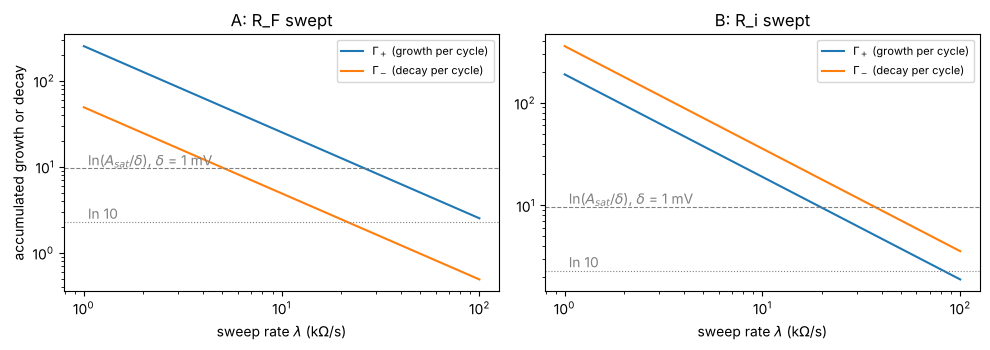

In [6]:
lam = np.logspace(3, 5, 300)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (name, Gk) in zip(axs, paths.items()):
    Sp = np.clip(Gk - G_C, 0, None).sum(); Sm = np.clip(G_C - Gk, 0, None).sum()
    ax.loglog(lam / 1e3, w0 * dR * Sp / lam, label=r"$\Gamma_+$ (growth per cycle)")
    ax.loglog(lam / 1e3, w0 * dR * Sm / lam, label=r"$\Gamma_-$ (decay per cycle)")
    ax.axhline(np.log(10), color="gray", ls=":", lw=0.8); ax.text(1.05, np.log(10) * 1.08, "ln 10", color="gray")
    ax.axhline(np.log(A_SAT / 1e-3), color="gray", ls="--", lw=0.8); ax.text(1.05, np.log(A_SAT / 1e-3) * 1.08, r"ln($A_{sat}/\delta$), $\delta$ = 1 mV", color="gray")
    ax.set_title(name); ax.set_xlabel(r"sweep rate $\lambda$ (k$\Omega$/s)"); ax.legend(fontsize=8)
axs[0].set_ylabel("accumulated growth or decay")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "budgets_vs_rate.png"), dpi=150); plt.show()

## Check against the report

In [7]:
checks = {
    "omega0 = 460.8 1/s (Eq. 2.6)": abs(w0 - 460.8) < 0.1,
    "k_off = 30.6 (Eq. 2.27)": abs(k_off - 30.6) < 0.1,
    "k_on = 53.9 / 62.0 / 69.2 (Table 2.2)": np.allclose(tab22.k_on, [53.9, 62.0, 69.2], atol=0.1),
    "k_i = 21.2 (Eq. 2.33 box)": abs(k_i - 21.2) < 0.05,
    "lambda_c(on), path A = 21.3 kOhm/s (Table 2.3)": abs(tab23.loc["lambda_c(on) [kOhm/s]", "A: R_F swept"] - 21.3) < 0.05,
    "lambda_c, path B = 26.1 / 19.8 / 16.0 kOhm/s (Table 2.3)": np.allclose(
        [tab23.loc[f"lambda_c, delta={d*1e3:g} mV [kOhm/s]", "B: R_i swept"] for d in NOISE_FLOORS], [26.1, 19.8, 16.0], atol=0.05),
}
for k, ok in checks.items(): print(("PASS " if ok else "FAIL ") + k)

PASS omega0 = 460.8 1/s (Eq. 2.6)
PASS k_off = 30.6 (Eq. 2.27)
PASS k_on = 53.9 / 62.0 / 69.2 (Table 2.2)
PASS k_i = 21.2 (Eq. 2.33 box)
PASS lambda_c(on), path A = 21.3 kOhm/s (Table 2.3)
PASS lambda_c, path B = 26.1 / 19.8 / 16.0 kOhm/s (Table 2.3)


## Using your own values

Change the component values in the INPUTS cell. Everything else follows. The formulas assume:
identical Wien arms (for unequal arms $G_c = 1 + R_1/R_2 + C_2/C_1$ and the prefactor of $\sigma$ becomes $1/(2R_1C_2)$), a potentiometer with `N_TAPS` evenly spaced taps, and a staircase in which every position is held twice per cycle.